In [1]:
# ==========================
# IMPORTS
# ==========================

import os
# import at
import time

import tango
import numpy as np
import pandas as pd

import pickle as pkl
import matplotlib.pyplot as plt
# import ringcontrol.beamcontrol.orbitcorr as orbitcorr
# from ringcontrol.devices.constants import DevNames, AttNames, PropNames, Numeric
# import ringcontrol.devices.magnets as magnets


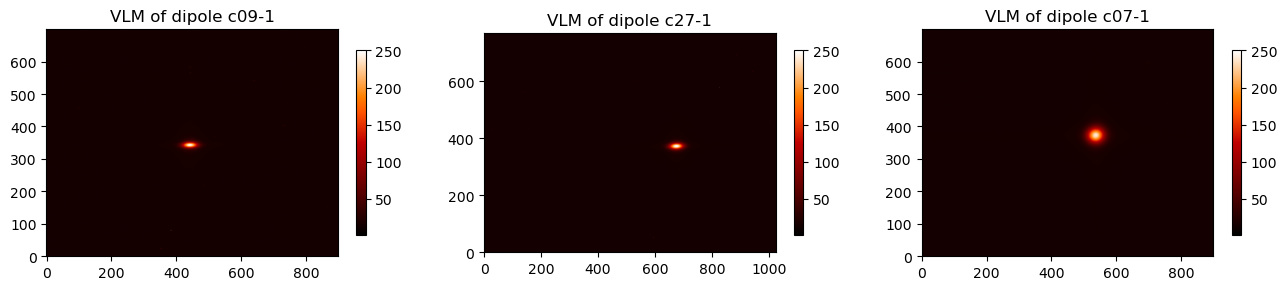

In [285]:
# Test of VLM images for SR
import matplotlib.colors as colors

fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for idx, d in enumerate(["c09-1", "c27-1", "c07-1"]):
    neg = ax[idx].imshow(tango.DeviceProxy(f'srdiag/ccd/{d}').Image, aspect='equal', origin='lower', cmap="gist_heat",
                         # norm=colors.LogNorm(),
                         vmin=0, vmax=250
                        )
    ax[idx].set_title(f"VLM of dipole {d}")
    fig.colorbar(neg, ax=ax[idx], shrink=0.4)

# plt.tight_layout()

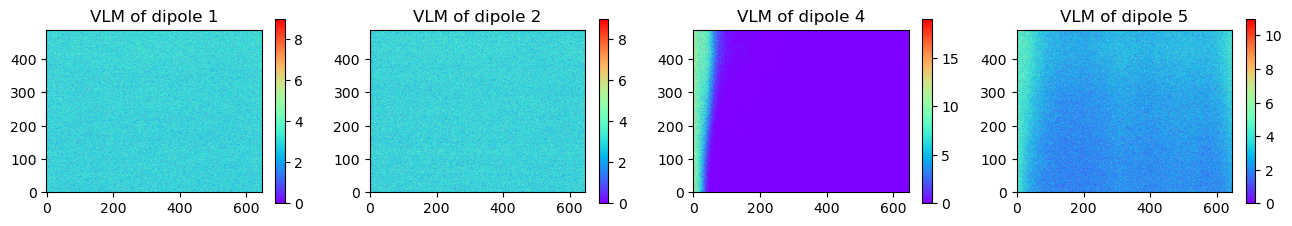

In [230]:
# Test of VLM images

fig, ax = plt.subplots(1, 4, figsize=(16, 6))
for idx, d in enumerate([1,2,4,5]):
    neg = ax[idx].imshow(tango.DeviceProxy(f'tl2/d-ccd/dipole{d}').Image, aspect='equal', origin='lower', cmap="rainbow")
    ax[idx].set_title(f"VLM of dipole {d}")
    fig.colorbar(neg, ax=ax[idx], shrink=0.4)

# plt.tight_layout()

In [219]:
# Set control system to work on simulator
os.environ["TANGO_HOST"] = "ebs-simu-1:10000"

In [225]:
# ==========================
# CONFIGURATION to connect to simulator "ebs-simu-1:10000" or the machine "acs.esrf.fr:10000,acs.esrf.fr:11000"
# ==========================

v = os.getenv("TANGO_HOST")
if v == "ebs-simu-1:10000":
    simulator = True
else:
    simulator = False

print("-.-" * 17)
print(f"\tScript running on {v}")
print("-.-" * 17)

-.--.--.--.--.--.--.--.--.--.--.--.--.--.--.--.--.-
	Script running on ebs-simu-1:10000
-.--.--.--.--.--.--.--.--.--.--.--.--.--.--.--.--.-


In [227]:
class InterfaceESRF_TL2():
    def get_name(self):
        return "ESRF_TL2_Ext"
        
    def __init__(self, nsamples=3, bg_shots=10.0):
        print(os.getenv("TANGO_HOST"))
        self.settle_time = 2
        self.calibration_pixel = 26e-6 # vlm calibration --> 26um per pixel
        self.chosen_ict = "tl2/d-ct/ict-1"
        self.nsamples = nsamples
        self.electronmass = 0.51099895 # MeV/c^2
        self.machine_name = "TL2"
        # self.tracking_interface = InterfaceESRF_TL2_RFTrack()
        self.is_simulation = False
        self.log = print

        # sequence including -- bpms and correctors -- in beamline order with device names
        # sequence = [
        #     "tl2/ps-c1/cv0", "tl2/d-bpm/cv1", "tl2/ps-c1/cv1", "tl2/ps-c1/ch1", "tl2/ps-c1/ch2", "tl2/ps-c1/cv3", "tl2/ps-c1/ch3", "tl2/d-bpm/d2",
        #     "tl2/d-bpm/q5", "tl2/ps-c1/cv4", "tl2/ps-c1/ch4", "tl2/d-bpm/q6", "tl2/ps-c1/cv5", "tl2/ps-c1/ch5", "tl2/d-bpm/sx",
        #     "tl2/ps-c1/cv6", "tl2/ps-c1/ch6", "tl2/d-bpm/q8", "tl2/ps-c1/cv7", "tl2/ps-c1/ch7", "tl2/d-bpm/q12", 
        #     "tl2/ps-c1/cv8", "tl2/ps-c1/ch8", "tl2/d-bpm/q14", "tl2/ps-c1/cv9", "tl2/d-bpm/s1pm"
        # ]
        # sequence including -- correctors and bpms -- in beamline order
        # sequence = [
        #     "COR.cv0", "BPM.cv1", "COR.cv1", "COR.ch1", "COR.ch2", "COR.cv3", "COR.ch3", "BPM.d2", "BPM.q5", 
        #     "COR.cv4", "COR.ch4", "BPM.q6", "COR.cv5", "COR.ch5", "BPM.sx", "COR.cv6", "COR.ch6", "BPM.q8", 
        #     "COR.cv7", "COR.ch7", "BPM.q12", "COR.cv8", "COR.ch8", "BPM.q14", "COR.cv9", "BPM.s1pm"
        # ]
        # sequence including correctors (COR), quadrupoles (MAG), dipoles (MAG) and bpms (BPM) -- in beamline order
        # sequence = [
            # "COR.cv0", "BPM.cv1", "COR.cv1", "COR.ch1", "MAG.qf1", "COR.ch2", "MAG.qd2", "MAG.d1", "MAG.qf3", "COR.cv3", "COR.ch3",
            # "MAG.d2", "BPM.d2", "MAG.qf4", "BPM.q5", "MAG.qd5", "COR.cv4", "COR.ch4", "BPM.q6", "MAG.qf6", "COR.cv5", "COR.ch5", "MAG.d3", 
            # "BPM.sx", "COR.cv6", "COR.ch6", "MAG.qf7", "MAG.d4", "BPM.q8", "MAG.qd8", "COR.cv7", "COR.ch7", "MAG.qf9", "MAG.qd10", "MAG.qf11", 
            # "MAG.d5", "BPM.q12", "MAG.qd12", "COR.cv8", "COR.ch8", "MAG.qf13", "BPM.q14", "MAG.qf14", "COR.cv9", "BPM.s1pm"
        # ]
        # sequence including correctors, quadrupoles and bpms -- in beamline order
        sequence = [
            "COR.cv0", "BPM.cv1", "COR.cv1", "COR.ch1", "MAG.qf1", "COR.ch2", "MAG.qd2", "MAG.qf3", "COR.cv3", "COR.ch3", "BPM.d2",
            "MAG.qf4", "BPM.q5", "MAG.qd5", "COR.cv4", "COR.ch4", "BPM.q6", "MAG.qf6", "COR.cv5", "COR.ch5", "BPM.sx",
            "COR.cv6", "COR.ch6", "MAG.qf7", "BPM.q8", "MAG.qd8", "COR.cv7", "COR.ch7", "MAG.qf9", "MAG.qd10", "MAG.qf11", "BPM.q12", 
            "MAG.qd12", "COR.cv8", "COR.ch8", "MAG.qf13", "BPM.q14", "MAG.qf14", "COR.cv9", "BPM.s1pm"
        ]
        monitors = [
            "CV1", "D2", "Q5", "Q6", "SX", "Q8", "Q12", "Q14", "S1PM" # striplines
        ]
        correctors = [
                   'CV0',
            'CH1', 'CV1',
            'CH2',
            'CH3', 'CV3',
            'CH4', 'CV4',
            'CH5', 'CV5',
            'CH6', 'CV6',
            'CH7', 'CV7',
            'CH8', 'CV8',
                   'CV9'
        ]
        quadrupoles = [
            "QF1", "QD2", "QF3", "QF4", "QD5", "QF6", "QF7", "QD8", "QF9", "QD10", "QF11", "QD12", "QF13", "QF14"
        ]
        vlm = [
            "D1", "D2", "D3", "D4", "D5" # visible light monitors
        ]
        screens = [
            "FS0", "FS1", "FS2", "FS3", "FS4", "FS5", "FS6", "FS7" # destructive screen measurements
        ]
        
        self.vlm = vlm
        self.bpms = monitors
        self.sequence = sequence
        self.screens = screens
        self.correctors = correctors
        self.quadrupoles = quadrupoles

    def get_sequence(self):
        "List sequence elements"
        return self.sequence
        
    def get_correctors(self):
        "List orbit correctors"
        return self.correctors
        
    def get_hcorrectors_names(self):
        "List HORIZONTAL orbit correctors"
        return [element for element in self.correctors if element[1] == "H"]

    def get_vcorrectors_names(self):
        "List VERTICAL orbit correctors"
        return [element for element in self.correctors if element[1] == "V"]
        
    def get_bpms(self):
        "List striplines"
        return self.bpms

    def get_icts(self):
        "List ICTs, which are striplines and integrated charge from ict"
        self.log("Reading ICT's... (charge from striplines, integrated charge from ict)")
        return {
            "names": self.bpms,
            "charge": tango.DeviceProxy('tl2/d-bpm/all').charge,
            "integrated_charge": tango.DeviceProxy('tl2/d-ct/ict-1').totalcharge,
        }

    def read_bpms(self):
        "Read BPMs/Striplines, x, y, and charge"
        self.log('Reading bpms...')
        return {
            "names": self.bpms,
            "x": tango.DeviceProxy('tl2/d-bpm/all').x_position,
            "y": tango.DeviceProxy('tl2/d-bpm/all').y_position,
            "signal": tango.DeviceProxy('tl2/d-bpm/all').charge
        }

    def read_vlm(self):
        "Read VLMs pixels 488x648"
        fig, ax = plt.subplots(1, 4, figsize=(16, 6))
        a, b = [], []
        for idx, d in enumerate([1,2,4,5]):
            ax[idx].imshow(tango.DeviceProxy(f'tl2/d-ccd/dipole{d}').Image, aspect='equal', origin='lower', cmap="rainbow")
            ax[idx].set_title(f"VLM of dipole {d}")
            a.append(f"Dipole{d}"); b.append(tango.DeviceProxy(f'tl2/d-ccd/dipole{d}').Image)
        return {
            "names": a,
            "2d_array": b
        }

    def read_charge(self):
        "Read striplines charge and ICT for integrated charge"
        self.log("Reading ICT's... (charge from striplines, integrated charge from ict)")
        return {
            "names": self.bpms,
            "charge": tango.DeviceProxy('tl2/d-bpm/all').charge,
            "integrated_charge": tango.DeviceProxy('tl2/d-ct/ict-1').totalcharge,
        }
    
    def set_correctors(self, names, values=None):
        "Set corrector currents to values"
        if names == "all":
            names = self.correctors
        elif isinstance(names, str):
            names = [names]
        if not isinstance(values, (list, tuple, np.ndarray)):
            values = [values]
        if len(names) != len(values):
            print('Error: len(names) != len(values) in set_correctors(names, values)')
            return
        for name, value in zip(names, values):
            print(f"Corrector {name} changed to {value}A with device -> 'tl2/ps-c1/{name.lower()}/current'")
            # commented to not change the machine by mistake
            # tango.AttributeProxy(f'tl2/ps-c1/{name.lower()}/current').write(value)
        time.sleep(self.settle_time)

    def reset_correctors(self):
        "Reset corrector (and quadrupole) currents to nominal operation parameters"
        tl2_mag = pd.read_csv("/opt/infra_rw/settings/tl2/operation.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        srinj_mag = pd.read_csv("/opt/infra_rw/settings/srinj-slowk/operation_restart.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        self.log(f"Reset correctors to operation file (operation.ts in tl2 & operation_restart in srinj)..")
        for element in self.correctors:
            if element in ["CV8", "CV9"]: # CV8 and CV9 currents saved in srinj file
                print(element.lower())
                # commented to not change the machine by mistake
                # tango.AttributeProxy(f'tl2/ps-c1/{element.lower()}/current').write(srinj_mag[srinj_mag["name"]==f'tl2/ps-c1/{element.lower()}/current']["current"].values[0])
            else:
                print(element.lower())
                print(tl2_mag[tl2_mag["name"]==f'tl2/ps-c1/{element.lower()}/current']["name"].values[0], tl2_mag[tl2_mag["name"]==f'tl2/ps-c1/{element.lower()}/current']["current"].values[0])
                # commented to not change the machine by mistake
                # tango.AttributeProxy(f'tl2/ps-c1/{element.lower()}/current').write(tl2_mag[tl2_mag["name"]==f'tl2/ps-c1/{element.lower()}/current']["current"].values[0])

    def set_quadrupoles(self, names, values=None):
        "Set quadrupole currents to values"
        if names == "all":
            names = self.quadrupoles
        elif isinstance(names, str):
            print(f"change {names} into {[names]}")
            names = [names]
        if not isinstance(values, (list, tuple, np.ndarray)):
            print(f"change {values} into {[values]}")
            values = [values]
        if len(names) != len(values):
            print('Error: len(names) != len(values) in set_correctors(names, values)')
            return
        for name, value in zip(names, values):
            print(f"Quad {name} changed to {value}A with device -> 'tl2/ps/{name.lower()}/current'")
            # commented to not change the machine by mistake
            # tango.AttributeProxy(f'tl2/ps/{name.lower()}/current').write(value)
        time.sleep(self.settle_time)

    def reset_quadrupoles(self):
        "Reset quadrupole currents to nominal operation parameters"
        tl2_mag = pd.read_csv("/opt/infra_rw/settings/tl2/operation.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        self.log(f"Reset quadrupoles to operation file..")
        for element in self.quadrupoles:
            print(tl2_mag[tl2_mag["name"]==f'tl2/ps/{element.lower()}/current']["name"].values[0], tl2_mag[tl2_mag["name"]==f'tl2/ps/{element.lower()}/current']["current"].values[0])
            # commented to not change the machine by mistake
            # tango.AttributeProxy(f'tl2/ps/{element.lower()}/current').write(tl2_mag[tl2_mag["name"]==f'tl2/ps/{element.lower()}/current']["current"].values[0])
    
    def change_energy(self, delta=None):
        "Change energy with extraction time in the booster"
        "which is good because the dipoles ramp in TL2 and SY (booster) are synchronised"
        df = pd.read_csv("/machfs/kandre/rips_dipole_ramp.csv")
        timing = pd.read_csv("/opt/infra_rw/settings/Timing/operation_short.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        syext = pd.read_csv("/opt/infra_rw/settings/syext/operation.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        Eext = np.interp(144.2 - delta, df["step"]/1599*250, df["Dipole Output Current [Amp]"]) * 4.05776e-3
        print(rf"For a dt = {-delta:.2f} ms, the extraction energy is ~ {Eext:.3f} GeV eq. to dpp = {1e2*(1-Eext/6):.2f}%")
        factor =  1 - (1-Eext/6)
        self.log(f"Change energy by {delta} which change the energy to {Eext:.2f}GeV ({1e2*(1-Eext/6):.2f}%)..")
        if delta is not None and abs(delta) < 5: # limit to 10ms Text variation
            try:
                # commented to not change the machine by mistake
                # tango.AttributeProxy('infra/t-whist/bunchclock/Text').write(timing[timing["name"]=="infra/t-whist/bunchclock/Text"]["current"].values[0] + delta)
                # tango.AttributeProxy('sy/ps-ke/1/current').write(syext[syext["name"]=="sy/ps-ke/1/current"]["current"].values[0] * factor)
                # tango.AttributeProxy('sy/ps-bumper/1/current').write(syext[syext["name"]=="sy/ps-bumper/1/current"]["current"].values[0]* factor)
                # tango.AttributeProxy('sy/ps-se/1/current').write(syext[syext["name"]=="sy/ps-se/1/current"]["current"].values[0]* factor)
                # tango.AttributeProxy('sy/ps-bumper/2/current').write(syext[syext["name"]=="sy/ps-bumper/2/current"]["current"].values[0]* factor)
                # tango.AttributeProxy('sy/ps-se/2-1/current').write(syext[syext["name"]=="sy/ps-se/2-1/current"]["current"].values[0]* factor)
                # tango.AttributeProxy('sy/ps-bumper/3/current').write(syext[syext["name"]=="sy/ps-bumper/3/current"]["current"].values[0]* factor)
            except Exception as e:
                self.log(f"ABORT : change_energy failed - {e}")
            finally:
                self.reset_energy()
                
    def reset_energy(self):
        "Reset extraction time to the nominal value from operation_short.ts"
        timing = pd.read_csv("/opt/infra_rw/settings/Timing/operation_short.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        syext = pd.read_csv("/opt/infra_rw/settings/syext/operation.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        self.log("Reset energy, with initial Text..")
        # commented to not change the machine by mistake
        # tango.AttributeProxy('infra/t-whist/bunchclock/Text').write(timing[timing["name"]=="infra/t-whist/bunchclock/Text"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-ke/1/current').write(syext[syext["name"]=="sy/ps-ke/1/current"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-bumper/1/current').write(syext[syext["name"]=="sy/ps-bumper/1/current"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-se/1/current').write(syext[syext["name"]=="sy/ps-se/1/current"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-bumper/2/current').write(syext[syext["name"]=="sy/ps-bumper/2/current"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-se/2-1/current').write(syext[syext["name"]=="sy/ps-se/2-1/current"]["current"].values[0])
        # tango.AttributeProxy('sy/ps-bumper/3/current').write(syext[syext["name"]=="sy/ps-bumper/3/current"]["current"].values[0])
        self.log(f"Write {timing[timing["name"]=="infra/t-whist/bunchclock/Text"]["current"].values[0]} to Text and {tango.AttributeProxy('infra/t-whist/bunchclock/Text').read().w_value} is read")
        
    def change_intensity(self, delta=None):
        "Change bunch intensity with grid voltage"
        self.log(f"Change intensity by {delta} on gridV..")
        if delta is not None and abs(delta) < 10:
            try:
                # commented to not change the machine by mistake
                # tango.DeviceProxy('elin/beam/run').gridv += delta
            except Exception as e:
                self.log(f"ABORT : change_intensity failed - {e}")
            finally:
                self.reset_intensity()
    
    def reset_intensity(self):
        "Reset bunch intensity with nominal value from operation_short.ts""
        linac = pd.read_csv("/opt/infra_rw/settings/linac/operation_short.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")
        self.log("Reset intensity..")
        # commented to not change the machine by mistake
        # tango.AttributeProxy('elin/beam/run/gridv').write(linac[linac["name"]=="elin/beam/run/gridv"]["current"].values[0])
        self.log(f"Write {linac[linac["name"]=="elin/beam/run/gridv"]["current"].values[0]} to GridV and {tango.AttributeProxy('elin/beam/run/gridv').read().w_value} is read")
        

In [277]:
pd.read_csv("/opt/infra_rw/settings/syext/operation.ts", header=None, names=["name", "current"], skiprows=6, sep=": ", engine="python")

,name,current
0,sy/ps-ke/1/current,1026.000
1,sy/t-ke/0/delay,2024.225
2,sy/t-ke/0/width,10.990
3,sy/t-ke/charge/delay,-5000.000
4,sy/t-ke/charge/width,10.000
5,sy/ps-bumper/1/current,199.250
6,infra/t-spare-injext/B1_firing/delay,141300.000
7,infra/t-spare-injext/B1_firing/width,100.000
8,sy/ps-se/1/current,3005.000
9,sy/t-se1/0/delay,1351.487


In [228]:
# Test interface/class

TL2 = InterfaceESRF_TL2()
TL2.get_sequence()

ebs-simu-1:10000


['COR.cv0',
 'BPM.cv1',
 'COR.cv1',
 'COR.ch1',
 'MAG.qf1',
 'COR.ch2',
 'MAG.qd2',
 'MAG.qf3',
 'COR.cv3',
 'COR.ch3',
 'BPM.d2',
 'MAG.qf4',
 'BPM.q5',
 'MAG.qd5',
 'COR.cv4',
 'COR.ch4',
 'BPM.q6',
 'MAG.qf6',
 'COR.cv5',
 'COR.ch5',
 'BPM.sx',
 'COR.cv6',
 'COR.ch6',
 'MAG.qf7',
 'BPM.q8',
 'MAG.qd8',
 'COR.cv7',
 'COR.ch7',
 'MAG.qf9',
 'MAG.qd10',
 'MAG.qf11',
 'BPM.q12',
 'MAG.qd12',
 'COR.cv8',
 'COR.ch8',
 'MAG.qf13',
 'BPM.q14',
 'MAG.qf14',
 'COR.cv9',
 'BPM.s1pm']

(-10.0, 260.0)

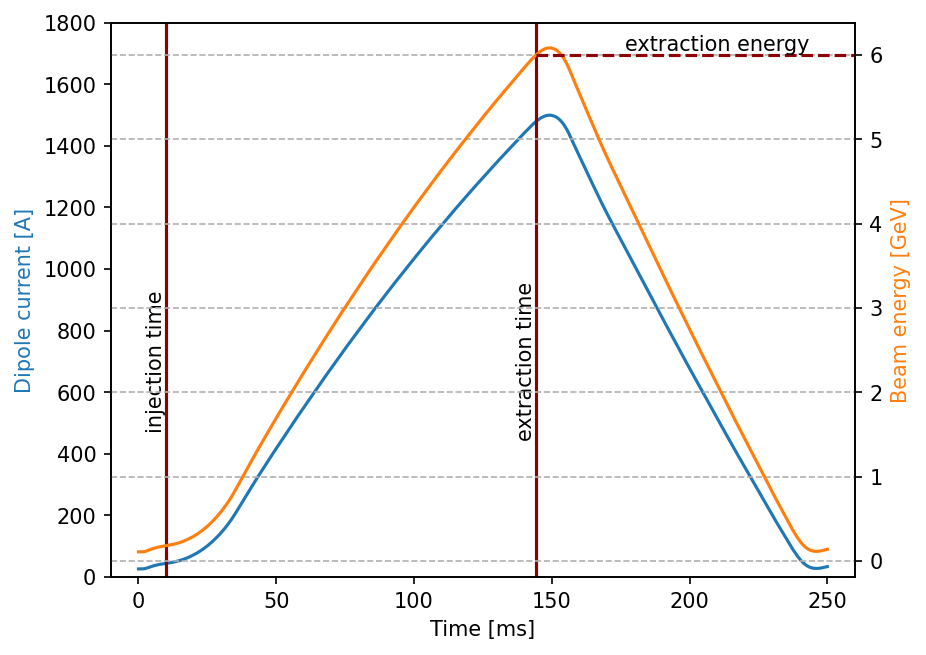

In [249]:
# RIPS ramp loading to interpolate the beam energy at extraction of the booster assuming 6GeV at nominal Text 
# Energy estimation in GeV is 4.05776e-3 x the dipole output current in Amperes

df = pd.read_csv("/machfs/kandre/rips_dipole_ramp.csv")

fig , ax = plt.subplots(dpi=150)
ax2 = ax.twinx()
ax.plot(df["step"]/1599*250, df["Dipole Output Current [Amp]"])

ax2.plot(df["step"]/1599*250, df["Dipole Output Current [Amp]"]*4.05776e-3, "C1")

ax.vlines(10.13, 0, 1800, 'darkred')
ax.text(10.13, 700, "injection time", rotation=90, va="center", ha="right")

ax.vlines(144.200, 0, 1800, 'darkred')
ax.text(144.2, 700, "extraction time", rotation=90, va="center", ha="right")

ax2.hlines(6, 144.200, 300, 'darkred', '--')
ax2.text(210, 6, "extraction energy", va="bottom", ha="center")

ax.set_xlabel("Time [ms]")
ax.set_ylabel("Dipole current [A]", color="C0")
# ax2.set_yscale("log")
ax2.set_ylabel("Beam energy [GeV]", color="C1")
ax2.grid(ls="--", which="both")
ax.set_ylim(0, 1800)
ax.set_xlim(-10, 260)

# interpolation
# x = np.linspace(0, 250, 501)
# plt.plot(x, np.interp(x, df["step"]/1599*250, df["Dipole Output Current [Amp]"]))

In [289]:
# Energy at injection into the booster
print(f"{np.interp(10.13 + 1, df["step"]/1599*250, df["Dipole Output Current [Amp]"]) * 4.05776:.1f} MeV")

186.5 MeV


In [290]:
for dt in np.linspace(0, 10, 11):
    Eext = np.interp(144.2 + 1 - dt, df["step"]/1599*250, df["Dipole Output Current [Amp]"]) * 4.05776e-3
    print(rf"For a dt = {-dt:.2f} ms, the extraction energy is ~ {Eext:.2f} GeV eq. to dpp = {1e2*(1-Eext/6):.2f}%")

For a dt = -0.00 ms, the extraction energy is ~ 6.03 GeV eq. to dpp = -0.49%
For a dt = -1.00 ms, the extraction energy is ~ 6.00 GeV eq. to dpp = -0.00%
For a dt = -2.00 ms, the extraction energy is ~ 5.97 GeV eq. to dpp = 0.54%
For a dt = -3.00 ms, the extraction energy is ~ 5.93 GeV eq. to dpp = 1.13%
For a dt = -4.00 ms, the extraction energy is ~ 5.90 GeV eq. to dpp = 1.74%
For a dt = -5.00 ms, the extraction energy is ~ 5.86 GeV eq. to dpp = 2.37%
For a dt = -6.00 ms, the extraction energy is ~ 5.82 GeV eq. to dpp = 3.00%
For a dt = -7.00 ms, the extraction energy is ~ 5.78 GeV eq. to dpp = 3.63%
For a dt = -8.00 ms, the extraction energy is ~ 5.74 GeV eq. to dpp = 4.27%
For a dt = -9.00 ms, the extraction energy is ~ 5.71 GeV eq. to dpp = 4.91%
For a dt = -10.00 ms, the extraction energy is ~ 5.67 GeV eq. to dpp = 5.56%
